In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops_table
from skimage.segmentation import expand_labels, clear_border, relabel_sequential
from PIL import Image, ImageOps
import pandas as pd
import networkx as nx
from scipy.spatial.distance import cdist


In [2]:
%cd /home/nodokaizm/code/mrcnn_multi_domain

/home/nodokaizm/code/mrcnn_multi_domain


## 準備：ライブラリ、パス、ラベル、カラーマップ定義

In [3]:
# --- セル1: G, G_vpr, G_vpの構築 ---

import os
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops_table
from skimage.segmentation import expand_labels, relabel_sequential
from PIL import Image, ImageOps
import pandas as pd
import networkx as nx

# 対象画像ID一覧
img_ids = [
    'acapod2_01_img.png',
    'alllit2_01_img.png',
    'burspi1_01_img.png',
    'euclon1_01_img.png',
    'exostr8_01_img.png',
    'hakdac2_01_img.png'
]

# ディレクトリ設定
gt_dir = 'dataset/performance_check/mask'

# グレイレベルとクラス
gray = [0, 64, 128, 192, 255]
cell_type = ['vessel', 'ray', 'fiber', 'parenchyma', 'stuff']
gr_cell_dict = dict(zip(gray, cell_type))

results = []

for img_id in img_ids:
    print(f"Processing: {img_id}")
    
    gt_path = os.path.join(gt_dir, img_id.replace('_img.png', '_msk.png'))
    gt_image = Image.open(gt_path).convert('L')
    gt_array = np.array(gt_image)
    inverted_gt = np.array(ImageOps.invert(gt_image))

    raw_labels = label(inverted_gt > 0)
    expanded_labels = expand_labels(raw_labels, distance=40)
    relabeled, _, _ = relabel_sequential(expanded_labels)

    props = regionprops_table(relabeled, properties=('label', 'centroid'))
    df = pd.DataFrame(props)

    def get_main_gray(label_val):
        pixels = gt_array[relabeled == label_val]
        pixels = pixels[pixels != 255]
        if len(pixels) == 0:
            return -1
        return int(np.argmax(np.bincount(pixels)))

    df['gray'] = [get_main_gray(lbl) for lbl in df['label']]
    df['anatomy'] = df['gray'].map(gr_cell_dict).fillna('unknown')

    node_coords = df[['centroid-0', 'centroid-1']].values
    node_labels = df['label'].values
    G = nx.Graph()

    for idx, lbl in enumerate(node_labels):
        anatomy = df.loc[df['label'] == lbl, 'anatomy'].values[0]
        if anatomy in ['vessel', 'parenchyma', 'ray']:
            x, y = node_coords[idx][1], node_coords[idx][0]
            G.add_node(lbl, pos=(x, y), anatomy=anatomy)

    # 隣接関係構築
    adjacency = set()
    h, w = relabeled.shape
    for y in range(h):
        for x in range(w):
            current = relabeled[y, x]
            if current == 0:
                continue
            for dy, dx in [(-1,0),(1,0),(0,-1),(0,1)]:
                ny, nx_ = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx_ < w:
                    neighbor = relabeled[ny, nx_]
                    if neighbor != 0 and neighbor != current:
                        adjacency.add(tuple(sorted((current, neighbor))))

    # エッジ追加（VPR間のみ）
    for a, b in adjacency:
        if a in G.nodes and b in G.nodes:
            G.add_edge(a, b)

    # anatomy取得
    node_anatomy = nx.get_node_attributes(G, 'anatomy')
    G_vpr = G.copy()
    G_vp = G.subgraph([n for n in G.nodes if node_anatomy[n] in ['vessel', 'parenchyma']]).copy()

    pos_vpr = {n: G.nodes[n]['pos'] for n in G_vpr.nodes}
    pos_vp = {n: G.nodes[n]['pos'] for n in G_vp.nodes}


    # parenchyma分類（意図に基づく）
    vessel_nodes = {n for n, d in G_vpr.nodes(data=True) if d['anatomy'] == 'vessel'}
    ray_nodes = {n for n, d in G_vpr.nodes(data=True) if d['anatomy'] == 'ray'}
    parenchyma_nodes = {n for n, d in G_vpr.nodes(data=True) if d['anatomy'] == 'parenchyma'}
    
    # G_vpネットワーク内の parenchyma（直接vesselと接続している）
    vp_connected_p = set()
    for comp in nx.connected_components(G_vp):
        if vessel_nodes & comp:
            vp_connected_p.update(comp & parenchyma_nodes)
    

    # --- 既存：type_A（=vp_connected_p）はそのままでOK ---
    type_A = vp_connected_p
    
    # --- 追加：G_vpr 上で vessel に到達できる parenchyma を取る ---
    vpr_connected_p = set()
    for comp in nx.connected_components(G_vpr):
        comp_set = set(comp)
        if vessel_nodes & comp_set:                      # VPRでvesselを含む成分
            vpr_connected_p.update(comp_set & parenchyma_nodes)
    
    # --- 意図どおりの Type B / C ---
    type_B = vpr_connected_p - type_A                   # VPRではVに届くがVPでは届かない
    type_C = parenchyma_nodes - vpr_connected_p         # VPRでもVに届かない
    


    # 色付け
    full_node_color_map = {}
    for n, d in G_vpr.nodes(data=True):
        if d['anatomy'] == 'vessel':
            full_node_color_map[n] = 'yellow'
        elif d['anatomy'] == 'ray':
            full_node_color_map[n] = 'gray'
        elif d['anatomy'] == 'parenchyma':
            if n in type_A:
                full_node_color_map[n] = '#e79ca9'
            elif n in type_B:
                full_node_color_map[n] = '#7898e1'
            elif n in type_C:
                full_node_color_map[n] = '#c78cd5'
            else:
                full_node_color_map[n] = 'black'

    results.append({
        'img_id': img_id,
        'gt_np': gt_array,
        'G': G,
        'G_vpr': G_vpr,
        'G_vp': G_vp,
        'pos_vpr': pos_vpr,
        'pos_vp': pos_vp,
        'full_node_color_map': full_node_color_map
    })


Processing: acapod2_01_img.png
Processing: alllit2_01_img.png
Processing: burspi1_01_img.png
Processing: euclon1_01_img.png
Processing: exostr8_01_img.png
Processing: hakdac2_01_img.png


# VPRの部分グラフ

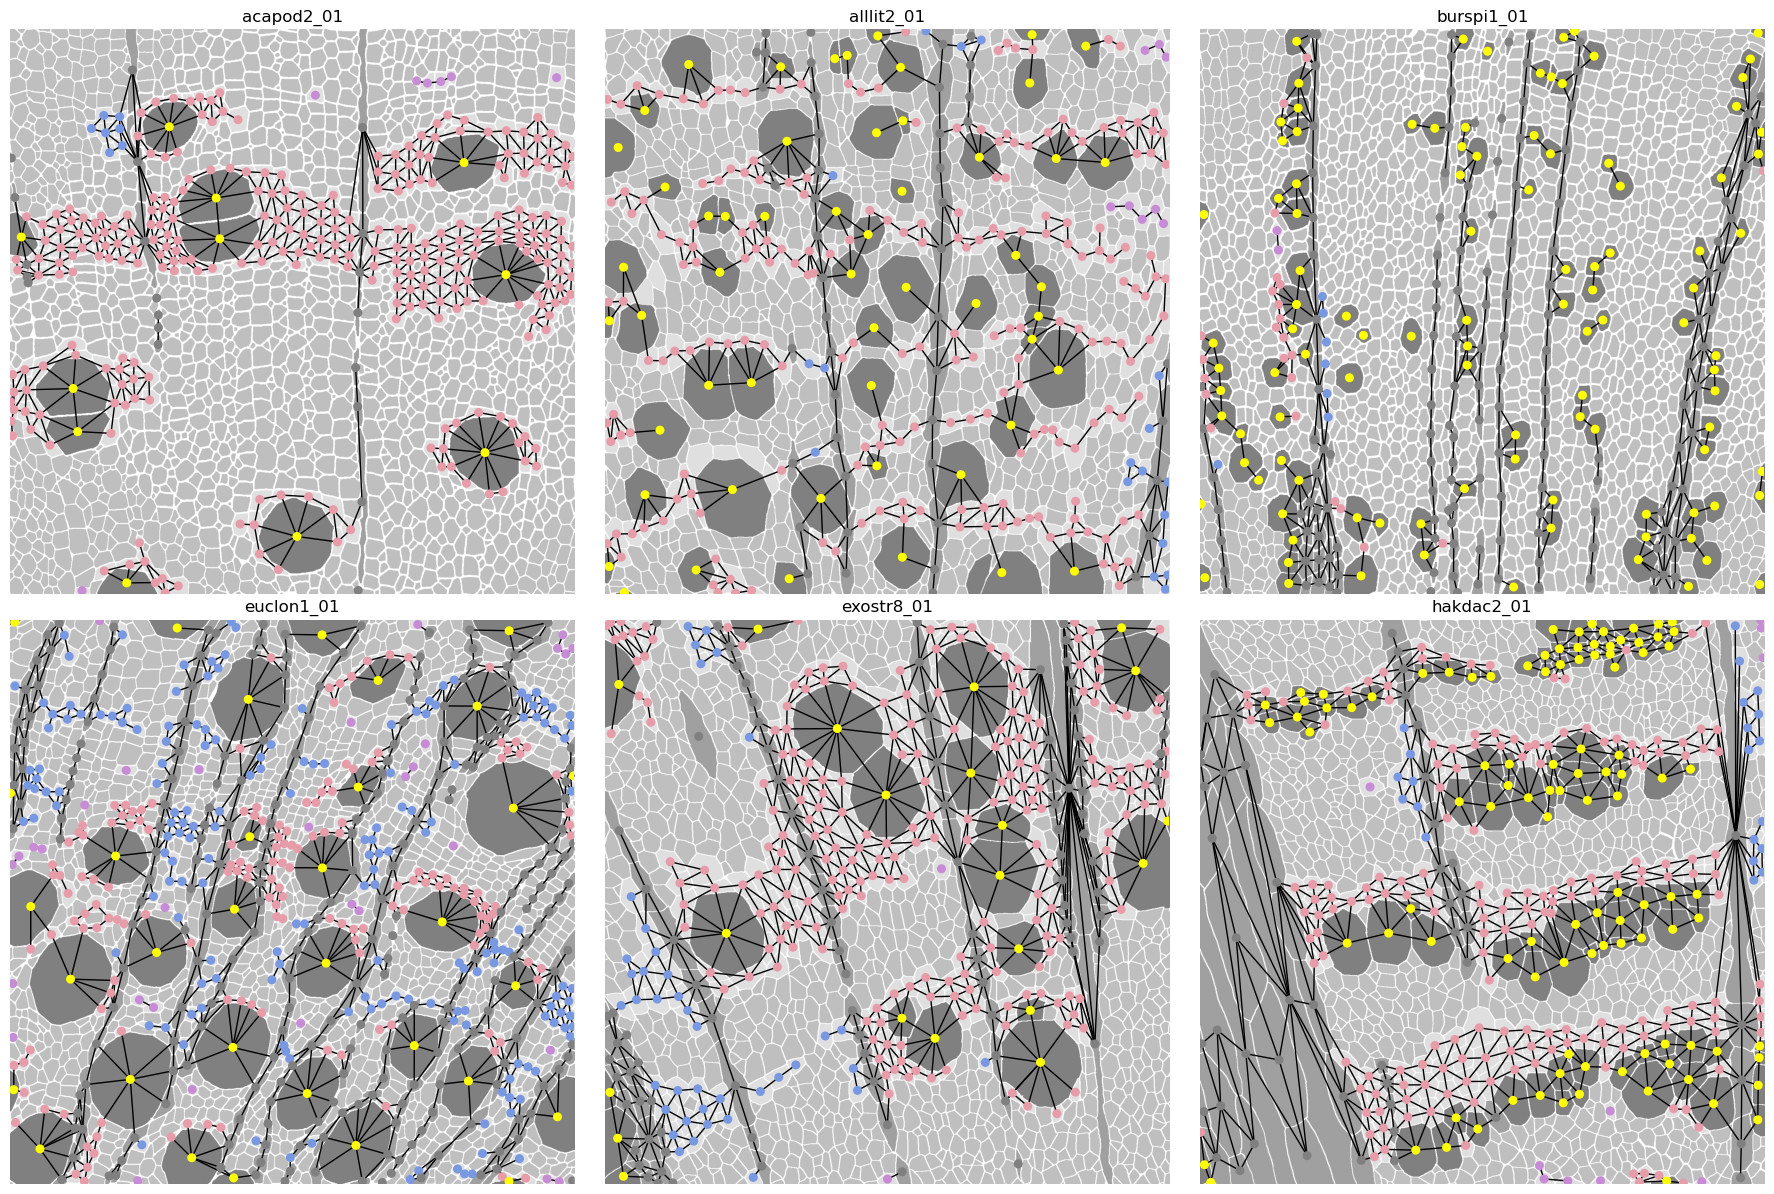

In [4]:
# --- Visualise G_vpr ---

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for idx, res in enumerate(results):
    ax = axes[idx // 3, idx % 3]
    ax.set_title(res['img_id'].replace('_img.png', ''))
    img = res['gt_np']
    h, w = img.shape[:2]
    ax.imshow(img, cmap='gray', alpha=0.5, extent=(0, w, h, 0))

    G = res['G_vpr']
    pos = res['pos_vpr']
    colors = [res['full_node_color_map'][n] for n in G.nodes()]

    nx.draw(G, pos, node_color=colors, edge_color='black', node_size=30, ax=ax, with_labels=False)
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')

plt.tight_layout()

# ---- save ----
out_path_pdf = os.path.join("plots_dfs", "G_vpr_panels.pdf")

fig.savefig(out_path_pdf, bbox_inches="tight")

plt.show()
